# AH2179 Project — Traffic Flow Short-Term Prediction

## Notebook roadmap

This notebook is the complete Pampas–Hornsberg project workflow. It runs two parallel flow forecasts during 07:30–08:30, updated each minute: (1) detector/lane flow (`DP_ID`) and (2) total location/portal flow (`PORTAL`). The target is **total flow during the following 15 minutes**, not a single observation 15 minutes later. Speed is retained as a predictor and is flow-weighted when sensors are aggregated to a portal.

**Data governance:** the supplied data must stay local and must never be committed or published. The modelling rule is chronological: use 2021 only for development and model selection; do not tune on any 2022 data. After locking the design, evaluate the official 2022 file once. Confirm with the instructor whether `evaluation_dataset.csv` or `final_evaluation_dataset.csv` is the required final file.

## 1. Research questions and hypotheses

1. Can recent flow/speed measurements and time-of-day predict the **total flow in t+1 through t+15** for each detector/lane (`DP_ID`)?
2. Can the same information predict the **total flow in t+1 through t+15** at each highway location (`PORTAL`)?
3. Does using upstream portal information improve local forecasts, and is 5-minute aggregation more robust than raw 1-minute data?

A-priori hypotheses: recent lags should be strongest at 15 minutes; rolling trends and upstream lags should become more useful at 30/60 minutes; weekday/season effects should help across months. Test these claims rather than assuming them.

## End-to-end process

Run the notebook in this order: **(1)** define the detector and portal targets; **(2)** audit and clean the 1-minute data; **(3)** compare 1/5/15-minute resolutions; **(4)** engineer only past-available features; **(5)** split 2021 chronologically; **(6)** train and tune models; **(7)** compare all models on the same validation period; **(8)** diagnose the selected model; **(9)** refit on 2021; **(10)** evaluate once on the official 2022 data; **(11)** save the selected Keras model and write the deployment recommendation.

For every result table and graph, add a short written interpretation to the report: what happened, why it may have happened, and what decision it supports.

In [ ]:
# 2222
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
HORIZON = 15
DATA_DIR = Path('data/dataset_for_traffic_project_assignment')
TRAIN_PATH = DATA_DIR / 'training_dataset.csv'
DEV_EVAL_PATH = DATA_DIR / 'evaluation_dataset.csv'
FINAL_EVAL_PATH = DATA_DIR / 'final_evaluation_dataset.csv'
MODEL_PATH = Path('models') / 'best_traffic_model.keras'
Path('models').mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')

## 2. Load and audit the raw data

Use semicolon parsing. Verify schema, duplicate sensor-minute observations, coverage, missing values and zeros. A zero speed is not automatically invalid: compare it with flow before choosing to impute, retain, or flag it.

In [65]:
def load_raw(path):
    df = pd.read_csv(path, sep=';')
    df['timestamp'] = pd.to_datetime(df['Date'].astype(str) + ' ' + df['Time'])
    return df.sort_values(['DP_ID', 'timestamp']).reset_index(drop=True)

train_raw = load_raw(TRAIN_PATH)
train_raw.shape, train_raw.head()

((1921967, 12),
    DP_ID      PORTAL      Date      Time  Interval_1  Interval_5  Interval_15  \
 0    153  E4S 56,490  20210601  04:00:00         240          48           16   
 1    153  E4S 56,490  20210601  04:01:00         241          48           16   
 2    153  E4S 56,490  20210601  04:02:00         242          48           16   
 3    153  E4S 56,490  20210601  04:03:00         243          48           16   
 4    153  E4S 56,490  20210601  04:04:00         244          48           16   
 
    Interval_30  Interval_60  SPEED_MS_AVG  FLOW           timestamp  
 0            8            4         27.50   1.0 2021-06-01 04:00:00  
 1            8            4         25.57  11.0 2021-06-01 04:01:00  
 2            8            4         23.83  12.0 2021-06-01 04:02:00  
 3            8            4         24.59  10.0 2021-06-01 04:03:00  
 4            8            4         27.36   5.0 2021-06-01 04:04:00  )

In [66]:
audit = pd.DataFrame({
    'dtype': train_raw.dtypes.astype(str),
    'missing': train_raw.isna().sum(),
    'n_unique': train_raw.nunique(),
})
display(audit)
print('Duplicate sensor-minutes:', train_raw.duplicated(['DP_ID', 'timestamp']).sum())
display(train_raw.groupby('DP_ID')[['FLOW', 'SPEED_MS_AVG']].agg(['count', 'mean', 'median', 'std']))
display(pd.crosstab(train_raw['FLOW'].eq(0), train_raw['SPEED_MS_AVG'].eq(0), normalize='all'))

,dtype,missing,n_unique
DP_ID,int64,0,29
PORTAL,object,0,8
Date,int64,0,214
Time,object,0,361
Interval_1,int64,0,361
Interval_5,int64,0,73
Interval_15,int64,0,25
Interval_30,int64,0,13
Interval_60,int64,0,7
SPEED_MS_AVG,float64,0,2944


Duplicate sensor-minutes: 0


FLOW                             SPEED_MS_AVG                    \
       count       mean median       std        count       mean median   
DP_ID                                                                     
153    70069  13.406314   13.0  7.592074        70069  23.180928  23.09   
351    65398  13.035919   14.0  5.638403        65398  18.286206  18.14   
353    72983  14.821671   16.0  6.988171        72983  16.193261  16.43   
534    69212  11.838727   12.0  6.790822        69212  20.200872  20.19   
536    69430  13.199554   13.0  7.584056        69430  23.294422  23.20   
539    73578  12.811955   14.0  5.596537        73578  19.606942  19.53   
543    73756  15.133467   16.0  6.807797        73756  17.553826  17.49   
740    74047  19.139047   21.0  7.083077        74047  20.832551  20.69   
749    73984  19.015990   21.0  7.185573        73984  17.857476  18.05   
751    74201  17.740933   19.0  6.594491        74201  19.288582  19.14   
902    73933  16.554705   18.0  7.077330        73933  19.950620  19.83   
1076   73954  14.651378   16.0  6.386678        73954  18.950216  18.90   
1079   73938  16.912481   18.0  6.592638        73938  18.265008  18.22   
1254   68940  12.357891   12.0  7.073302        68940  22.697915  22.64   
1443   71135  13.593955   14.0  7.670989        71135  19.631845  19.78   
4427   57798  10.413544   10.0  7.613069        57802  23.173537  23.06   
4428   74568  13.497090   14.0  8.353386        74568  21.356614  21.39   
4429   62245  11.088344   10.0  8.374601        62252  22.966745  23.06   
4430   65869  14.094263   15.0  8.642839        65870  20.009711  20.00   
4436   52082  10.960293   10.0  7.513911        52082  18.722668  18.61   
4437   72641  10.758029   10.0  7.493332        72645  18.600337  18.61   
4439   54773   2.942672    2.0  2.080563        54776  19.696881  19.44   
4472   58557   9.867001    9.0  7.173166        58564  25.602116  25.56   
4473   74447  12.776620   13.0  7.771176        74447  21.616659  21.39   
4494   50591   9.673855    9.0  6.645252        50591  19.910331  19.72   
4495   60955   3.871479    3.0  2.652357        60974  21.198660  21.11   
4496   49149   2.799487    2.0  2.000798        49166  17.249748  17.22   
4872   56048   3.385206    3.0  2.320954        56048  17.401255  17.22   
4873   53624   4.803894    4.0  3.645934        53624  17.483207  17.22   

                 
            std  
DP_ID            
153    2.257717  
351    1.824708  
353    2.133354  
534    2.011877  
536    2.296311  
539    1.708135  
543    1.936835  
740    1.980211  
749    2.335546  
751    2.038016  
902    2.081368  
1076   1.909497  
1079   1.998583  
1254   2.237066  
1443   2.338761  
4427   2.185589  
4428   2.051100  
4429   2.375741  
4430   2.033514  
4436   1.961573  
4437   1.948322  
4439   2.444171  
4472   2.222635  
4473   1.988182  
4494   1.914301  
4495   2.379693  
4496   2.069299  
4872   2.255328  
4873   1.923852

SPEED_MS_AVG,False,True
FLOW,,
False,0.999999,0.000001


## 2a. Clean and normalise the data

Missing `FLOW` values are retained as missing until the forecast target is built—an unobserved future flow must never become a label. Missingness flags are kept as model features. The model pipeline imputes feature values using a median learned from its training rows only, so no future observation leaks into a past forecast. Zero speed is retained but flagged because it can mean stopped traffic. Numeric predictors are normalised by `StandardScaler`, fitted on the training period only; `target_flow` is not normalised.

In [67]:
def clean_detector_data(df):
    x = df.copy().sort_values(['DP_ID', 'timestamp']).reset_index(drop=True)
    x['FLOW'] = pd.to_numeric(x['FLOW'], errors='coerce')
    x['SPEED_MS_AVG'] = pd.to_numeric(x['SPEED_MS_AVG'], errors='coerce')
    x['flow_was_missing'] = x['FLOW'].isna().astype('int8')
    x['flow_observed'] = x['FLOW'].notna()
    x['speed_was_missing'] = x['SPEED_MS_AVG'].isna().astype('int8')
    x['speed_was_zero'] = x['SPEED_MS_AVG'].eq(0).astype('int8')
    # Do not fill observations here: feature imputation belongs inside a pipeline fitted on training data only.
    return x

train_clean = clean_detector_data(train_raw)
display(train_clean[['FLOW', 'SPEED_MS_AVG']].isna().sum().rename('missing values retained for safe pipeline imputation'))
display(train_clean[['flow_was_missing', 'speed_was_missing', 'speed_was_zero']].sum().rename('flagged rows'))

FLOW            62
SPEED_MS_AVG     0
Name: missing values retained for safe pipeline imputation, dtype: int64

flow_was_missing     62
speed_was_missing     0
speed_was_zero        2
Name: flagged rows, dtype: int64

## 2a(i). Audit zeros and missing values at 1-, 5-, and 15-minute resolution

This test decides aggregation rather than assuming it. For each detector, aggregate flow by summing observed one-minute counts and calculate a flow-weighted mean speed. A block with any missing one-minute observation is labelled incomplete; it is not treated as zero. Compare the fraction of incomplete blocks and zero-flow blocks across resolutions, plus the loss of temporal detail.

Decision rule: retain 1-minute data if missingness is negligible and short shocks matter; prefer 5 minutes if it materially reduces incomplete/noisy observations while preserving the peak pattern; use 15 minutes only when the operational forecast is explicitly a 15-minute total, because it loses minute-by-minute responsiveness.

In [68]:
def resolution_audit(df, minutes):
    x = df[['DP_ID', 'timestamp', 'FLOW', 'SPEED_MS_AVG']].copy()
    x['block'] = x['timestamp'].dt.floor(f'{minutes}min')
    x['speed_x_flow'] = x['SPEED_MS_AVG'] * x['FLOW']
    grouped = x.groupby(['DP_ID', 'block'])
    out = grouped.agg(flow_total=('FLOW', lambda s: s.sum(min_count=minutes)),
                      observed_minutes=('FLOW', 'count'),
                      speed_x_flow=('speed_x_flow', 'sum'))
    out['incomplete_block'] = out['observed_minutes'].lt(minutes)
    out['zero_flow_block'] = out['flow_total'].eq(0)
    out['speed_flow_weighted'] = out['speed_x_flow'].div(out['flow_total']).where(out['flow_total'].ne(0))
    return out.reset_index()

resolution_summary = []
for minutes in (1, 5, 15):
    audit_df = resolution_audit(train_clean, minutes)
    resolution_summary.append({'resolution_min': minutes, 'blocks': len(audit_df),
                               'incomplete_%': 100 * audit_df.incomplete_block.mean(),
                               'zero_flow_%': 100 * audit_df.zero_flow_block.mean(),
                               'missing_weighted_speed_%': 100 * audit_df.speed_flow_weighted.isna().mean()})
resolution_comparison = pd.DataFrame(resolution_summary)
display(resolution_comparison)
# Write the chosen resolution and numerical evidence in the report.

,resolution_min,blocks,incomplete_%,zero_flow_%,missing_weighted_speed_%
0,1,1921967,0.003226,0.0,0.003226
1,5,420925,18.864168,0.0,18.864168
2,15,146314,28.529054,0.0,28.529054


## 2a(ii). Encoding, scaling, and handling missing model inputs

`DP_ID`, `PORTAL`, weekday, and month are categorical. One-hot encoding is used for Ridge and the MLP; the boosting model receives a documented integer encoding. The `SimpleImputer` and `StandardScaler` sit inside the pipeline, so both learn only from the chronological training split. Missingness flags remain features after imputation. This is the correct point to handle unknown/missing *inputs*; missing labels have already been excluded.

## 2b. Create the two prediction units

The supplied description calls `DP_ID` a sensor ID and says each portal has several sensors per line. It does not explicitly label the physical lane number, so describe this carefully as **detector/lane-level** rather than claiming a verified lane label. There are 29 DP_IDs across 8 portals (3–5 sensors per portal).

For the location task, sum lane flows at the same portal-minute. A portal speed must be flow-weighted: `sum(speed × flow) / sum(flow)`. Keep the number of reporting detectors as a quality feature, because a lower count could mean a missing detector rather than lower traffic.

In [69]:
def aggregate_to_portal(df):
    x = df.copy()
    x['speed_x_flow'] = x['SPEED_MS_AVG'] * x['FLOW']
    keys = ['PORTAL', 'timestamp']
    portal = (x.groupby(keys, as_index=False)
                .agg(FLOW=('FLOW', lambda s: s.sum(min_count=len(s))),
                     speed_x_flow=('speed_x_flow', 'sum'),
                     reporting_detectors=('DP_ID', 'nunique'),
                     portal_flow_was_missing=('flow_was_missing', 'max')))
    portal['SPEED_MS_AVG'] = portal['speed_x_flow'].div(portal['FLOW']).where(portal['FLOW'].ne(0))
    return portal.drop(columns='speed_x_flow').sort_values(keys).reset_index(drop=True)

portal_raw = aggregate_to_portal(train_clean)
display(train_raw.groupby('PORTAL')['DP_ID'].nunique().rename('detectors_per_portal'))
display(portal_raw.head())

PORTAL
E4S 55,620    3
E4S 56,160    3
E4S 56,490    4
E4S 56,780    4
E4S 57,055    3
E4S 57,435    3
E4S 57,820    4
E4S 58,140    5
Name: detectors_per_portal, dtype: int64

,PORTAL,timestamp,FLOW,reporting_detectors,portal_flow_was_missing,SPEED_MS_AVG
0,"E4S 55,620",2021-06-01 04:00:00,29.0,3,0,21.683103
1,"E4S 55,620",2021-06-01 04:01:00,26.0,3,0,21.933077
2,"E4S 55,620",2021-06-01 04:02:00,38.0,3,0,21.563684
3,"E4S 55,620",2021-06-01 04:03:00,34.0,3,0,22.681176
4,"E4S 55,620",2021-06-01 04:04:00,29.0,3,0,23.126552


## 3. Descriptive analysis (Task A)

Produce figures that answer both *when* and *where*: distributions, median morning profiles by portal/sensor, flow–speed relationship, and missingness/zero patterns. In the report, caption each plot with an interpretation rather than only describing it.

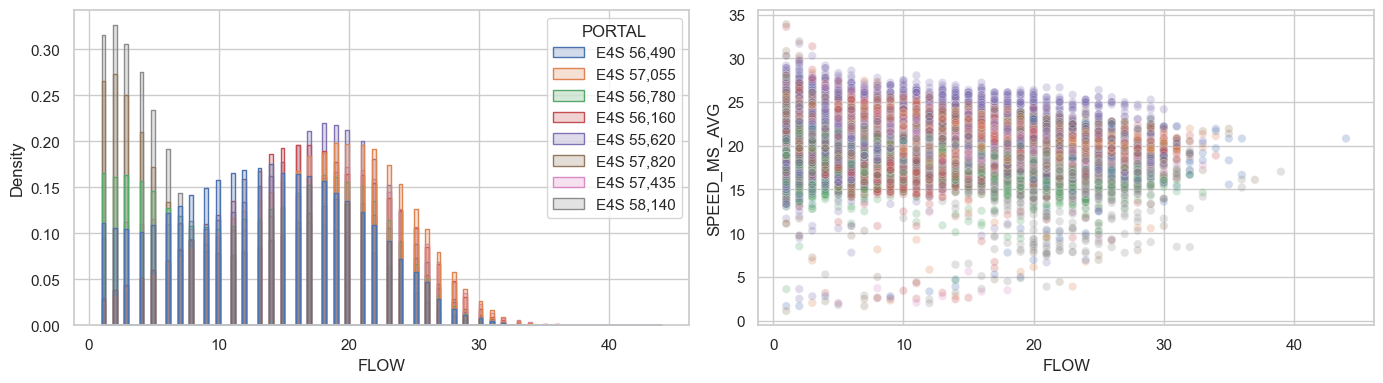

In [70]:
morning = train_clean.loc[train_clean['timestamp'].dt.strftime('%H:%M').between('07:00', '09:00')].copy()
morning['minute_of_day'] = morning['timestamp'].dt.hour * 60 + morning['timestamp'].dt.minute
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(morning, x='FLOW', hue='PORTAL', element='step', stat='density', common_norm=False, ax=axes[0])
sns.scatterplot(data=morning.sample(min(20_000, len(morning)), random_state=RANDOM_STATE), x='FLOW', y='SPEED_MS_AVG', hue='PORTAL', alpha=.25, legend=False, ax=axes[1])
plt.tight_layout()

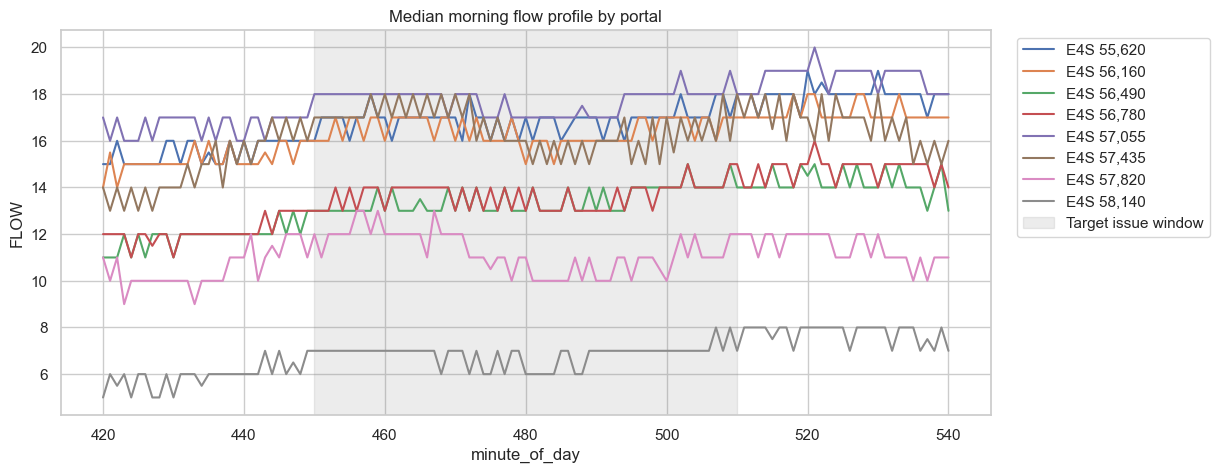

In [71]:
profile = morning.groupby(['PORTAL', 'minute_of_day'], as_index=False)['FLOW'].median()
plt.figure(figsize=(12, 5))
sns.lineplot(data=profile, x='minute_of_day', y='FLOW', hue='PORTAL')
plt.axvspan(450, 510, color='grey', alpha=.15, label='Target issue window')
plt.title('Median morning flow profile by portal'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.show()

## 4. Build a leakage-safe supervised dataset

Create the target by shifting **within each sensor and day**. Use only information available at prediction time. Drop rows whose future target is unavailable or whose timestamp gap means the target is not exactly 15 minutes ahead. The final scoring rows have forecast origins 07:30–08:30.

Start with 1-minute data, then repeat the same audit/model pipeline for a 5-minute aggregation as an explicit robustness comparison. Do not use future rolling windows, random row splits, or `Interval_*` values as substitutes for a forecast target.

In [72]:
def make_features(df, entity_col, horizon=15):
    x = df.copy().sort_values([entity_col, 'timestamp'])
    x['date'] = x['timestamp'].dt.normalize()
    g = x.groupby([entity_col, 'date'], sort=False)
    # Target: total vehicles during the next 15 one-minute intervals, t+1 ... t+15.
    future_flow = pd.concat([g['FLOW'].shift(-step) for step in range(1, horizon + 1)], axis=1)
    x['target_flow'] = future_flow.sum(axis=1, min_count=horizon)
    x['target_timestamp'] = g['timestamp'].shift(-horizon)  # end of forecast window
    for lag in (1, 5, 10, 15, 30, 60):
        x[f'flow_lag_{lag}'] = g['FLOW'].shift(lag)
        x[f'speed_lag_{lag}'] = g['SPEED_MS_AVG'].shift(lag)
    x['flow_roll_5'] = g['FLOW'].transform(lambda s: s.shift(1).rolling(5, min_periods=3).mean())
    x['flow_roll_15'] = g['FLOW'].transform(lambda s: s.shift(1).rolling(15, min_periods=8).mean())
    x['flow_sum_15'] = g['FLOW'].transform(lambda s: s.shift(1).rolling(15, min_periods=15).sum())
    x['speed_roll_5'] = g['SPEED_MS_AVG'].transform(lambda s: s.shift(1).rolling(5, min_periods=3).mean())
    x['minute_of_day'] = x['timestamp'].dt.hour * 60 + x['timestamp'].dt.minute
    x['weekday'] = x['timestamp'].dt.weekday
    x['month'] = x['timestamp'].dt.month
    x['minute_sin'] = np.sin(2 * np.pi * x['minute_of_day'] / 1440)
    x['minute_cos'] = np.cos(2 * np.pi * x['minute_of_day'] / 1440)
    valid_target = x['target_timestamp'].sub(x['timestamp']).dt.total_seconds().eq(horizon * 60)
    # min_count=horizon makes any incomplete future 15-minute label NaN; exclude it, never impute it.
    return x.loc[valid_target & x['target_flow'].notna()].copy()

lane_supervised = make_features(train_clean, entity_col='DP_ID', horizon=HORIZON)
portal_supervised = make_features(portal_raw, entity_col='PORTAL', horizon=HORIZON)
issue_window = lane_supervised['timestamp'].dt.strftime('%H:%M').between('07:30', '08:30')
lane_model_data = lane_supervised.loc[issue_window].copy()
portal_model_data = portal_supervised.loc[portal_supervised['timestamp'].dt.strftime('%H:%M').between('07:30', '08:30')].copy()
assert lane_model_data['target_flow'].notna().all() and portal_model_data['target_flow'].notna().all()
print('Lane/detector rows:', lane_model_data.shape, '| Portal rows:', portal_model_data.shape)
display(portal_model_data[['timestamp', 'PORTAL', 'FLOW', 'target_flow', 'reporting_detectors']].head())

Lane/detector rows: (307487, 40) | Portal rows: (102100, 30)


,timestamp,PORTAL,FLOW,target_flow,reporting_detectors
210,2021-06-01 07:30:00,"E4S 55,620",49.0,812.0,3
211,2021-06-01 07:31:00,"E4S 55,620",54.0,818.0,3
212,2021-06-01 07:32:00,"E4S 55,620",48.0,845.0,3
213,2021-06-01 07:33:00,"E4S 55,620",42.0,861.0,3
214,2021-06-01 07:34:00,"E4S 55,620",35.0,878.0,3


## 5. Chronological development split and baseline

Reserve the latest part of 2021 for validation (for example, October–December); use earlier months for training. This simulates deployment into a later period. Compare every learned model with persistence: `flow at t` as the 15-minute forecast.

In [73]:
# Run this section twice: once with 'lane' and once with 'portal'. Keep result tables separate.
MODEL_LEVEL = 'lane'  # choose 'lane' (DP_ID) or 'portal' (PORTAL total)
model_data = lane_model_data.copy() if MODEL_LEVEL == 'lane' else portal_model_data.copy()
SPLIT_DATE = pd.Timestamp('2021-10-01')
train_df = model_data.loc[model_data['timestamp'] < SPLIT_DATE].copy()
valid_df = model_data.loc[model_data['timestamp'] >= SPLIT_DATE].copy()

def metric_row(y_true, y_pred, name):
    # MAPE is unstable at zero; report its denominator rule explicitly.
    mask = y_true != 0
    return {'model': name, 'MAE': mean_absolute_error(y_true, y_pred),
            # Explicit square root is compatible with old and new scikit-learn versions.
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAPE_nonzero_%': 100 * np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask]))}

# Persistence needs an observed current flow; learned models can use the pipeline's training-only imputation.
baseline_valid = valid_df.dropna(subset=['flow_sum_15', 'target_flow'])
results = [metric_row(baseline_valid.target_flow, baseline_valid.flow_sum_15, '15-min persistence baseline')]
pd.DataFrame(results)

,model,MAE,RMSE,MAPE_nonzero_%
0,15-min persistence baseline,20.551168,28.495493,10.546584


## 6. Compare regression, neural networks, classification, and clustering-assisted models (Task C)

1. Persistence baseline (operational benchmark).  \n
2. Regularized linear regression (interpretable).  \n
3. Histogram gradient boosting regression (non-linear tabular model).  \n
4. Keras MLP regression (neural-network candidate, saved as `.keras` if selected).  \n
5. Flow-band classification, converted to a flow estimate with the predicted band midpoint.  \n
6. Clustering-assisted regression, with an unsupervised traffic-regime cluster as a feature.

Tune only on the chronological validation set (or expanding-window splits within 2021). Compare every approach using MAE/RMSE/MAPE in **vehicles/minute** on the same validation rows. Classification also reports accuracy and macro-F1, but those do not replace regression metrics. Choose the simplest model whose validation performance and diagnostic behaviour justify deployment.

In [74]:
target = 'target_flow'
categorical = (['DP_ID', 'PORTAL'] if MODEL_LEVEL == 'lane' else ['PORTAL']) + ['weekday', 'month']
numeric = [c for c in model_data.columns if c.startswith(('flow_lag_', 'speed_lag_', 'flow_roll_', 'flow_sum_', 'speed_roll_'))] + ['minute_sin', 'minute_cos']
numeric += [c for c in ['flow_was_missing', 'speed_was_missing', 'speed_was_zero', 'portal_flow_was_missing'] if c in model_data]
if MODEL_LEVEL == 'portal':
    numeric += ['reporting_detectors']
features = categorical + numeric

linear_prep = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
])
ridge = Pipeline([('prep', linear_prep), ('model', Ridge(alpha=10.0))])
ridge.fit(train_df[features], train_df[target])
results.append(metric_row(valid_df[target], ridge.predict(valid_df[features]), 'Ridge'))
pd.DataFrame(results).sort_values('MAE')

,model,MAE,RMSE,MAPE_nonzero_%
1,Ridge,19.078259,25.705804,10.717376
0,15-min persistence baseline,20.551168,28.495493,10.546584


In [75]:
# For boosting, ordinal-code categoricals after documenting the chosen encoding.
boost_features = features.copy()
boost_levels = {c: pd.Index(train_df[c].astype(str).unique()) for c in categorical}
def encode_for_boost(frame):
    encoded = frame[boost_features].copy()
    for c, levels in boost_levels.items():
        encoded[c] = levels.get_indexer(encoded[c].astype(str))
    return encoded

boost_train = encode_for_boost(train_df)
boost_valid = encode_for_boost(valid_df)
boost = HistGradientBoostingRegressor(max_iter=300, learning_rate=.08, max_leaf_nodes=31, l2_regularization=1, random_state=RANDOM_STATE)
boost.fit(boost_train, train_df[target])
results.append(metric_row(valid_df[target], boost.predict(boost_valid), 'Histogram gradient boosting'))
pd.DataFrame(results).sort_values('MAE')

,model,MAE,RMSE,MAPE_nonzero_%
2,Histogram gradient boosting,18.117961,24.696590,9.661109
1,Ridge,19.078259,25.705804,10.717376
0,15-min persistence baseline,20.551168,28.495493,10.546584


### Hyperparameter tuning on the chronological validation period

Tune only with 2021 training/validation rows. This small, transparent grid is intentionally limited so it remains feasible on the full dataset. Select the best setting by validation MAE, then retain its RMSE and MAPE for comparison. Do not use 2022 data here.

In [ ]:
ridge_tuning, boost_tuning = [], []
for alpha in [0.1, 1.0, 10.0, 100.0]:
    candidate = Pipeline([('prep', clone(linear_prep)), ('model', Ridge(alpha=alpha))])
    candidate.fit(train_df[features], train_df[target])
    ridge_tuning.append(metric_row(valid_df[target], candidate.predict(valid_df[features]), f'Ridge alpha={alpha}'))

boost_grid = {'learning_rate': [0.04, 0.08], 'max_leaf_nodes': [15, 31], 'l2_regularization': [0.0, 1.0]}
for params in ParameterGrid(boost_grid):
    candidate = HistGradientBoostingRegressor(max_iter=300, random_state=RANDOM_STATE, **params)
    candidate.fit(boost_train, train_df[target])
    score = metric_row(valid_df[target], candidate.predict(boost_valid), f'Boost {params}')
    score.update(params)
    boost_tuning.append(score)

tuning_results = pd.DataFrame(ridge_tuning + boost_tuning).sort_values('MAE').reset_index(drop=True)
display(tuning_results)
best_boost_params = tuning_results.loc[tuning_results.model.str.startswith('Boost')].iloc[0][['learning_rate', 'max_leaf_nodes', 'l2_regularization']].to_dict()
best_boost_params = {k: float(v) if k in ['learning_rate', 'l2_regularization'] else int(v) for k, v in best_boost_params.items()}
boost = HistGradientBoostingRegressor(max_iter=300, random_state=RANDOM_STATE, **best_boost_params).fit(boost_train, train_df[target])
results.append(metric_row(valid_df[target], boost.predict(boost_valid), 'Tuned histogram gradient boosting'))
pd.DataFrame(results).drop_duplicates('model', keep='last').sort_values('MAE')

,model,MAE,RMSE,MAPE_nonzero_%,l2_regularization,learning_rate,max_leaf_nodes
0,"Boost {'l2_regularization': 1.0, 'learning_rat...",17.616052,23.955380,9.500483,1.0,0.04,15.0
1,"Boost {'l2_regularization': 0.0, 'learning_rat...",17.622510,23.981909,9.464758,0.0,0.04,15.0
2,"Boost {'l2_regularization': 1.0, 'learning_rat...",17.780163,24.225692,9.511618,1.0,0.04,31.0
3,"Boost {'l2_regularization': 0.0, 'learning_rat...",17.822543,24.299327,9.533598,0.0,0.04,31.0
4,"Boost {'l2_regularization': 1.0, 'learning_rat...",17.852027,24.286967,9.609845,1.0,0.08,15.0
5,"Boost {'l2_regularization': 0.0, 'learning_rat...",17.878797,24.325555,9.645244,0.0,0.08,15.0
6,"Boost {'l2_regularization': 0.0, 'learning_rat...",18.113997,24.704607,9.665169,0.0,0.08,31.0
7,"Boost {'l2_regularization': 1.0, 'learning_rat...",18.117961,24.696590,9.661109,1.0,0.08,31.0
8,Ridge alpha=100.0,18.996235,25.651377,10.632310,NaN,NaN,NaN
9,Ridge alpha=10.0,19.078259,25.705804,10.717376,NaN,NaN,NaN


,model,MAE,RMSE,MAPE_nonzero_%
3,Tuned histogram gradient boosting,17.616052,23.955380,9.500483
2,Histogram gradient boosting,18.117961,24.696590,9.661109
1,Ridge,19.078259,25.705804,10.717376
0,15-min persistence baseline,20.551168,28.495493,10.546584


### Classification benchmark

Classification is possible only after converting continuous flow into discrete bands (here: low/medium/high/very-high training quantiles). It is useful for operational alerts, but it discards flow precision. To compare it fairly with regressors, convert each predicted class to its training-band midpoint and score that value against actual flow.

In [77]:
# Quantile edges come from training labels only.
flow_edges = np.unique(train_df[target].quantile([0, .25, .50, .75, 1]).to_numpy())
if len(flow_edges) < 3:
    raise ValueError('Too few distinct flow values to create classification bands')
y_train_class = pd.cut(train_df[target], bins=flow_edges, labels=False, include_lowest=True)
y_valid_class = pd.cut(valid_df[target], bins=flow_edges, labels=False, include_lowest=True)
flow_classifier = HistGradientBoostingClassifier(max_iter=300, learning_rate=.08, max_leaf_nodes=31, l2_regularization=1, random_state=RANDOM_STATE)
flow_classifier.fit(boost_train, y_train_class)
predicted_class = flow_classifier.predict(boost_valid)
band_midpoints = (flow_edges[:-1] + flow_edges[1:]) / 2
class_flow_prediction = band_midpoints[predicted_class]
results.append(metric_row(valid_df[target], class_flow_prediction, 'Flow-band classifier (midpoint)'))
class_mask = y_valid_class.notna()
classification_scores = {'accuracy': accuracy_score(y_valid_class[class_mask], predicted_class[class_mask]),
                         'macro_F1': f1_score(y_valid_class[class_mask], predicted_class[class_mask], average='macro')}
display(pd.DataFrame(results).sort_values('MAE'))
classification_scores

,model,MAE,RMSE,MAPE_nonzero_%
3,Tuned histogram gradient boosting,17.616052,23.955380,9.500483
2,Histogram gradient boosting,18.117961,24.696590,9.661109
1,Ridge,19.078259,25.705804,10.717376
0,15-min persistence baseline,20.551168,28.495493,10.546584
4,Flow-band classifier (midpoint),32.840771,41.120333,19.200061


{'accuracy': 0.7661123140000922, 'macro_F1': 0.7616578196138452}

### Clustering-assisted regression benchmark

Clustering alone does not predict a continuous future flow. It groups similar detectors/portals (or days) into regimes, then its cluster label can improve a regression model. This cell clusters entity profiles using only the training period and tests whether that extra feature helps Ridge.

In [78]:
entity_key = 'DP_ID' if MODEL_LEVEL == 'lane' else 'PORTAL'
profile_columns = ['FLOW', 'SPEED_MS_AVG', 'flow_roll_15']
entity_profiles = train_df.groupby(entity_key)[profile_columns].mean().fillna(train_df[profile_columns].median())
profile_scaled = StandardScaler().fit_transform(entity_profiles)
n_clusters = min(3, len(entity_profiles))
kmeans = KMeans(n_clusters=n_clusters, n_init=20, random_state=RANDOM_STATE).fit(profile_scaled)
cluster_map = pd.Series(kmeans.labels_, index=entity_profiles.index, name='traffic_cluster').astype(str)
train_clustered, valid_clustered = train_df.copy(), valid_df.copy()
train_clustered['traffic_cluster'] = train_clustered[entity_key].map(cluster_map)
valid_clustered['traffic_cluster'] = valid_clustered[entity_key].map(cluster_map).fillna('unknown')
cluster_categorical = categorical + ['traffic_cluster']
cluster_features = numeric + cluster_categorical
cluster_prep = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cluster_categorical),
])
ridge_cluster = Pipeline([('prep', cluster_prep), ('model', Ridge(alpha=10.0))])
ridge_cluster.fit(train_clustered[cluster_features], train_clustered[target])
results.append(metric_row(valid_clustered[target], ridge_cluster.predict(valid_clustered[cluster_features]), 'Ridge + traffic cluster'))
pd.DataFrame(results).sort_values('MAE')

,model,MAE,RMSE,MAPE_nonzero_%
3,Tuned histogram gradient boosting,17.616052,23.955380,9.500483
2,Histogram gradient boosting,18.117961,24.696590,9.661109
1,Ridge,19.078259,25.705804,10.717376
5,Ridge + traffic cluster,19.082890,25.708495,10.722792
0,15-min persistence baseline,20.551168,28.495493,10.546584
4,Flow-band classifier (midpoint),32.840771,41.120333,19.200061


In [79]:
# Neural-network regression benchmark. Run after Ridge so linear_prep is fitted on training rows only.
import tensorflow as tf
tf.keras.utils.set_random_seed(RANDOM_STATE)
X_train_nn = linear_prep.fit_transform(train_df[features])
X_valid_nn = linear_prep.transform(valid_df[features])
X_train_nn = (X_train_nn.toarray() if hasattr(X_train_nn, 'toarray') else X_train_nn).astype('float32')
X_valid_nn = (X_valid_nn.toarray() if hasattr(X_valid_nn, 'toarray') else X_valid_nn).astype('float32')
nn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_nn.shape[1],)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(.20),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1),
])
nn.compile(optimizer='adam', loss='mae', metrics=['mae'])
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_mae', patience=8, restore_best_weights=True)
nn.fit(X_train_nn, train_df[target], validation_data=(X_valid_nn, valid_df[target]), epochs=100, batch_size=1024, callbacks=[early_stop], verbose=1)
results.append(metric_row(valid_df[target], nn.predict(X_valid_nn, verbose=0).ravel(), 'Keras MLP regression'))
pd.DataFrame(results).sort_values('MAE')

Epoch 1/100
174/174 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 211.6896 - mae: 211.6896 - val_loss: 53.1382 - val_mae: 53.1382
Epoch 2/100
174/174 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 41.4984 - mae: 41.4984 - val_loss: 38.3850 - val_mae: 38.3850
Epoch 3/100
174/174 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 24.5622 - mae: 24.5622 - val_loss: 39.7508 - val_mae: 39.7508
Epoch 4/100
174/174 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 22.6111 - mae: 22.6111 - val_loss: 40.7454 - val_mae: 40.7454
Epoch 5/100
174/174 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 22.0423 - mae: 22.0423 - val_loss: 41.3353 - val_mae: 41.3353
Epoch 6/100
174/174 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 21.7922 - mae: 21.7922 - val_loss: 41.6641 - val_mae: 41.6641
Epoch 7/100
174/174 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 21.5340 - mae: 21.5340 - val_loss: 41.6890 - val_mae: 41.6890
Epoch 8/100
174/174 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 21.3618 - mae: 21.3618 - val_loss: 42.8232 - val_mae: 42.8232
Epoch 9/100
17

,model,MAE,RMSE,MAPE_nonzero_%
3,Tuned histogram gradient boosting,17.616052,23.955380,9.500483
2,Histogram gradient boosting,18.117961,24.696590,9.661109
1,Ridge,19.078259,25.705804,10.717376
5,Ridge + traffic cluster,19.082890,25.708495,10.722792
0,15-min persistence baseline,20.551168,28.495493,10.546584
4,Flow-band classifier (midpoint),32.840771,41.120333,19.200061
6,Keras MLP regression,38.384991,46.065297,18.730040


## 7. Diagnostics (Task D)

Evaluate the selected model by sensor, portal, weekday, month, and forecast-origin minute. Plot residuals and the worst days. Then simulate real-time degradation by masking selected lag values and adding bounded noise; compare metrics to the clean-input case. Finally, report a month-by-month validation table to assess generalizability.

,mean,median,count
PORTAL,,,
"E4S 55,620",19.544400,15.835183,15443
"E4S 57,055",19.275628,15.272576,15376
"E4S 56,160",19.063699,15.035741,15393
"E4S 56,490",18.537511,14.381118,16857
"E4S 56,780",17.753945,13.717871,18335
"E4S 57,435",17.627345,13.609907,13086
"E4S 57,820",15.178960,11.653212,16320
"E4S 58,140",14.738687,11.425276,19468


,mean,median,count
DP_ID,,,
153,25.641179,20.222590,4763
536,25.605200,21.079225,4763
534,25.320299,20.127624,4636
1254,24.917768,19.635746,4656
1443,24.696687,19.012380,4872
4429,21.885643,17.127317,4168
4472,21.573203,17.295009,3952
4427,21.058081,17.066067,3864
1076,17.743089,15.005426,5358


,mean,median,count
weekday,,,
Friday,19.917471,14.489836,20666
Monday,18.486811,14.377988,19478
Wednesday,18.363243,14.142828,19998
Thursday,18.064549,14.032636,20868
Tuesday,17.872820,14.267066,20718
Sunday,14.656644,11.638657,12721
Saturday,14.046878,11.933835,15829


month
2021-10    16.227850
2021-11    18.946691
2021-12    17.796858
Name: abs_error, dtype: float64

origin_minute
08:14    18.930673
08:13    18.918578
08:15    18.707030
08:16    18.674148
08:12    18.606055
07:30    18.494298
07:31    18.310893
08:17    18.260501
08:30    18.259736
07:50    18.231986
Name: abs_error, dtype: float64

date
2021-11-19    39.997235
2021-12-03    36.879264
2021-10-18    24.871483
2021-12-27    24.296270
2021-11-17    23.798503
2021-11-23    23.503231
2021-11-18    22.432797
2021-11-11    22.004871
2021-11-22    21.957154
2021-12-16    21.788131
Name: worst_daily_MAE, dtype: float64

,model,MAE,RMSE,MAPE_nonzero_%
0,Clean inputs,17.616052,23.955380,9.500483
1,5% noise in lag inputs,17.619939,23.957830,9.503757
2,Recent lag inputs missing,17.693282,24.056241,9.633007


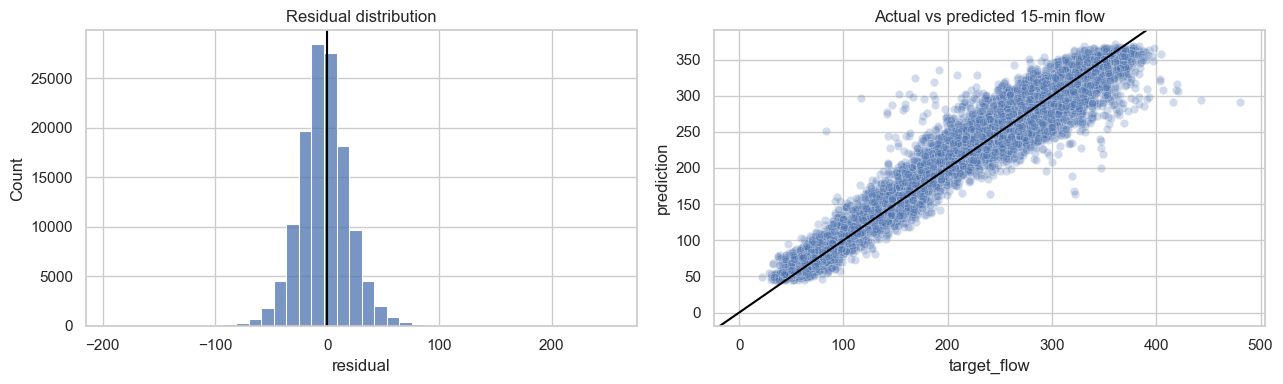

In [80]:
# Set this after examining the validation comparison table.
SELECTED_MODEL = 'boost'  # choose: 'ridge', 'boost', or 'mlp'
def selected_predict(frame):
    if SELECTED_MODEL == 'ridge':
        return ridge.predict(frame[features])
    if SELECTED_MODEL == 'boost':
        return boost.predict(encode_for_boost(frame))
    if SELECTED_MODEL == 'mlp':
        x_nn = linear_prep.transform(frame[features])
        x_nn = (x_nn.toarray() if hasattr(x_nn, 'toarray') else x_nn).astype('float32')
        return nn.predict(x_nn, verbose=0).ravel()
    raise ValueError('SELECTED_MODEL must be ridge, boost, or mlp')

entity_key = 'DP_ID' if MODEL_LEVEL == 'lane' else 'PORTAL'
diagnostic = valid_df[['timestamp', entity_key, 'PORTAL', 'target_flow']].copy()
diagnostic['prediction'] = selected_predict(valid_df)
diagnostic['residual'] = diagnostic.target_flow - diagnostic.prediction
diagnostic['abs_error'] = diagnostic.residual.abs()
display(diagnostic.groupby('PORTAL')['abs_error'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False))
diagnostic['month'] = diagnostic.timestamp.dt.to_period('M').astype(str)
diagnostic['weekday'] = diagnostic.timestamp.dt.day_name()
diagnostic['origin_minute'] = diagnostic.timestamp.dt.strftime('%H:%M')
display(diagnostic.groupby(entity_key)['abs_error'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False).head(10))
display(diagnostic.groupby('weekday')['abs_error'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False))
display(diagnostic.groupby('month')['abs_error'].mean())
display(diagnostic.groupby('origin_minute')['abs_error'].mean().sort_values(ascending=False).head(10))
display(diagnostic.assign(date=diagnostic.timestamp.dt.date).groupby('date')['abs_error'].mean().sort_values(ascending=False).head(10).rename('worst_daily_MAE'))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(diagnostic.residual, bins=40, ax=axes[0]); axes[0].axvline(0, color='black'); axes[0].set_title('Residual distribution')
sns.scatterplot(data=diagnostic.sample(min(10_000, len(diagnostic)), random_state=RANDOM_STATE), x='target_flow', y='prediction', alpha=.25, ax=axes[1])
axes[1].axline((0, 0), slope=1, color='black'); axes[1].set_title('Actual vs predicted 15-min flow'); plt.tight_layout()

# Robustness: use the same validation labels while degrading only real-time inputs.
rng = np.random.default_rng(RANDOM_STATE)
noisy_valid = valid_df.copy()
lag_columns = [c for c in numeric if c.startswith(('flow_lag_', 'speed_lag_'))]
for c in lag_columns:
    scale = train_df[c].std()
    noisy_valid[c] = noisy_valid[c] + rng.normal(0, 0.05 * scale, len(noisy_valid))
missing_valid = valid_df.copy()
missing_valid[[c for c in lag_columns if c in ['flow_lag_1', 'speed_lag_1', 'flow_lag_5', 'speed_lag_5']]] = np.nan
robustness = pd.DataFrame([
    metric_row(valid_df[target], selected_predict(valid_df), 'Clean inputs'),
    metric_row(valid_df[target], selected_predict(noisy_valid), '5% noise in lag inputs'),
    metric_row(valid_df[target], selected_predict(missing_valid), 'Recent lag inputs missing'),
]).sort_values('MAE')
display(robustness)

## 8. Lock the model and evaluate 2022

After choosing the pipeline and hyperparameters, refit it on all eligible 2021 data. Do not change it after inspecting 2022 results. Evaluate all valid 07:30–08:30 forecast origins in the supplied evaluation files for **both units**: per-detector/lane flow and total portal flow. Clearly label `evaluation_dataset.csv` as development evaluation and `final_evaluation_dataset.csv` as the final hold-out, unless the instructor specifies a different role.

In [81]:
# final_raw = load_raw(FINAL_EVAL_PATH)  # Run only after locking the design.
# final_clean = clean_detector_data(final_raw)
# final_data = make_features(final_clean, entity_col='DP_ID', horizon=HORIZON)  # lane run
# final_portal_data = make_features(aggregate_to_portal(final_clean), entity_col='PORTAL', horizon=HORIZON)  # portal run
# final_data = final_data.loc[final_data.timestamp.dt.strftime('%H:%M').between('07:30', '08:30')].copy()
# Refit the chosen preprocessing + model on all 2021 model_data, predict final_data, and save a metrics table.
# If the MLP wins: nn.save(MODEL_PATH)
# Otherwise document why a non-Keras model was selected and additionally train/save the required Keras final candidate if the course requires it.

## 9. Deployment recommendation and report checklist (Tasks E–F)

Proposed operational concept: every minute, validate incoming detector data, impute/flag unavailable lags, generate a 15-minute forecast with a confidence/quality flag, and display portal-specific warnings when predicted flow or speed crosses an agency-defined threshold. Monitor drift and retrain on a rolling schedule.

Before submission, ensure the report contains: objective; EDA figures; formulation and leakage controls; preprocessing and feature decisions; all model parameters and MAE/RMSE/MAPE comparison; diagnostics; final 2022 result; practical recommendation; limitations/future work; and a GitHub link with code only. Add `data/`, `*.csv`, and `models/` to `.gitignore` before publishing.